# Part II_Deep_Learning

## Group Members: Shishir Dahal, Royar Kurdman, Hashir Javed

## Model selection
We chose a 1-D CNN because the input is a raw vibration signal in which bearing faults appear as localized, repetitive impulses. Convolutional filters detect such local patterns independent of their position in the segment, and the network learns discriminative features directly from the waveform instead of relying on four hand-crafted statistics. Unlike an LSTM, a CNN trains efficiently on 2000-sample segments and has fewer parameters, which suits our dataset of 30,743 segments from 240 recordings.

## Task II.1 -- Engineering Problem and Dataset
### Question 1
The Part I dataset is reused: Paderborn bearing vibration signals (K001, KA01, KI01, all four operating conditions). The problem is bearing fault diagnosis, with a three-class target: healthy (0), outer-race damage (1) or inner-race damage (2).
### Question 2
The input is the raw `vibration_1` signal, cut into 2000-value segments. This gives an array of shape (30743, 2000, 1), from 240 recordings (about 10,250 segments per class).
### Question 3
A 1-D CNN is used because bearing faults appear as short, repeating impulses. Convolutional filters detect these local patterns at any position and learn features from the raw waveform.

## Task II.2 -- Data Preparation and Implementation
**Inputs and targets.** Every recording of `vibration_1` is cut into non-overlapping segments of 2000 samples (same segmentation as Part I). Each segment is one sample with shape (2000, 1); the target is the class label 0 = healthy (K001), 1 = outer race (KA01), 2 = inner race (KI01).

**Split without leakage.** Neighbouring segments of one recording are almost identical, so a segment-level random split would put near-copies of the same signal in train and test. We therefore split **by recording** (60 % / 20 % / 20 %, stratified per class, fixed seed). No recording contributes segments to more than one set. The standardisation constants (one mean and one standard deviation) are computed on the training set only and then applied to validation and test.

In [1]:
import os, glob, re, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)

DATA_DIR  = "dataset"     # folder with the extracted Paderborn .mat files (same as Part I)
SEG_LEN   = 2000
CONDITION = None          # None = all 4 operating conditions (as in Part I); e.g. "N15_M01_F10" for one condition
CLASSES = {"K001": 0, "KA01": 1, "KI01": 2}
NAMES   = {0: "Healthy", 1: "Outer race", 2: "Inner race"}
os.makedirs("figures", exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.22.0-rc1


In [2]:
def load_signal(path):
    """Return the vibration_1 signal of one .mat recording as a 1-D float array."""
    m = scipy.io.loadmat(path, squeeze_me=True, struct_as_record=False)
    key = [k for k in m if not k.startswith("__")][0]
    names = [y.Name for y in m[key].Y]
    return np.asarray(m[key].Y[names.index("vibration_1")].Data, float).ravel()

CACHE = f"segments_cache_{CONDITION or 'all'}.npz"      # speeds up re-runs; do NOT commit (see .gitignore)
if os.path.exists(CACHE):
    z = np.load(CACHE)
    X_all, y_all, rec_all = z["X"], z["y"], z["rec"]
else:
    X_list, y_list, rec_list = [], [], []
    for code_, label in CLASSES.items():
        files = sorted(glob.glob(os.path.join(DATA_DIR, "**", f"*{code_}*.mat"), recursive=True))
        if CONDITION:
            files = [f for f in files if CONDITION in os.path.basename(f)]
        print(f"{code_}: {len(files)} recordings")
        for path in files:
            sig = load_signal(path)
            n = len(sig) // SEG_LEN
            segs = sig[: n * SEG_LEN].reshape(n, SEG_LEN)
            segs = segs[segs.std(axis=1) > 0]                       # same rule as Part I
            X_list.append(segs.astype(np.float32))
            y_list.append(np.full(len(segs), label))
            rec_list.append(np.full(len(segs), os.path.basename(path)))
    if not X_list:
        raise FileNotFoundError(f"No .mat files found under {os.path.abspath(DATA_DIR)}")
    X_all, y_all, rec_all = np.concatenate(X_list), np.concatenate(y_list), np.concatenate(rec_list)
    np.savez_compressed(CACHE, X=X_all, y=y_all, rec=rec_all)

print("Segments:", X_all.shape, "| recordings:", len(np.unique(rec_all)))
print("Segments per class:", {NAMES[k]: int((y_all == k).sum()) for k in NAMES})

Segments: (30743, 2000) | recordings: 240
Segments per class: {'Healthy': 10246, 'Outer race': 10255, 'Inner race': 10242}


In [3]:
# ---- split BY RECORDING, stratified per class (60/20/20) ----
rec_tbl = pd.DataFrame({"rec": rec_all, "y": y_all}).drop_duplicates("rec")
rng = np.random.default_rng(SEED)
split_of = {}
for lab in NAMES:
    recs = np.array(sorted(rec_tbl.loc[rec_tbl.y == lab, "rec"]))
    rng.shuffle(recs)
    n_tr, n_va = int(round(0.6 * len(recs))), int(round(0.2 * len(recs)))
    split_of.update({r: "train" for r in recs[:n_tr]})
    split_of.update({r: "val"   for r in recs[n_tr:n_tr + n_va]})
    split_of.update({r: "test"  for r in recs[n_tr + n_va:]})

split = pd.Series(rec_all).map(split_of).values
tr, va, te = split == "train", split == "val", split == "test"

# leakage check: no recording in more than one set
sets = [set(rec_all[m]) for m in (tr, va, te)]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "recording leakage!"

summary = pd.DataFrame({s: [len(set(rec_all[m])), int(m.sum())] + [int((y_all[m] == k).sum()) for k in NAMES]
                        for s, m in zip(["train", "val", "test"], [tr, va, te])},
                       index=["recordings", "segments"] + [f"segments {NAMES[k]}" for k in NAMES])
print(summary)

# ---- standardisation fitted on TRAIN only (one global mean/std) ----
mu, sd = X_all[tr].mean(), X_all[tr].std()
print(f"train mean = {mu:.4f}, train std = {sd:.4f}")

X_train, y_train, rec_train = ((X_all[tr] - mu) / sd)[..., None], y_all[tr], rec_all[tr]
X_val,   y_val,   rec_val   = ((X_all[va] - mu) / sd)[..., None], y_all[va], rec_all[va]
X_test,  y_test,  rec_test  = ((X_all[te] - mu) / sd)[..., None], y_all[te], rec_all[te]
X_test_raw = X_all[te].copy()          # un-scaled copy, used later for plots and feature baseline
X_train_raw = X_all[tr].copy()
del X_all
print("X_train", X_train.shape, "| X_val", X_val.shape, "| X_test", X_test.shape)

                     train   val  test
recordings             144    48    48
segments             18452  6147  6144
segments Healthy      6147  2051  2048
segments Outer race   6161  2047  2047
segments Inner race   6144  2049  2049


train mean = -0.0153, train std = 0.4907

X_train (18452, 2000, 1) | X_val (6147, 2000, 1) | X_test (6144, 2000, 1)


### CNN architecture
The model is a 1-D CNN with two convolutional blocks, global average pooling and a softmax output layer.

| Layer | Output shape | Settings | Trainable parameters |
|---|---|---|---|
| Input | (2000, 1) | one vibration segment, standardised | 0 |
| Conv1D | (2000, 16) | 16 filters, kernel size 32, ReLU, `same` padding | 528 |
| MaxPooling1D | (500, 16) | pool size 4 | 0 |
| Conv1D | (500, 32) | 32 filters, kernel size 16, ReLU, `same` padding | 8 224 |
| MaxPooling1D | (125, 32) | pool size 4 | 0 |
| GlobalAveragePooling1D | (32,) | averages each filter over time | 0 |
| Dropout | (32,) | rate 0.3 (regularisation) | 0 |
| Dense | (3,) | softmax, one unit per class | 99 |
| **Total** | | | **8 851** |

**Main components.** The convolutional filters are learned detectors for short impulse patterns (the first, longer kernel covers 32 samples and works like a learned band-pass filter; the second, shorter kernel combines these into higher-level patterns). Max pooling reduces the sequence length and gives some shift tolerance. Global average pooling aggregates each filter over the whole segment, so the output does not depend on where in the segment an impulse occurs and the network needs no large dense layer. Dropout and the small parameter count limit overfitting.

In [4]:
def build_cnn(filters=(16, 32), kernels=(32, 16), pool=4, dropout=0.3, seed=SEED):
    keras.utils.set_random_seed(seed)
    return keras.Sequential([
        keras.Input(shape=(SEG_LEN, 1)),
        layers.Conv1D(filters[0], kernels[0], padding="same", activation="relu"),
        layers.MaxPooling1D(pool),
        layers.Conv1D(filters[1], kernels[1], padding="same", activation="relu"),
        layers.MaxPooling1D(pool),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(dropout),
        layers.Dense(len(NAMES), activation="softmax"),
    ], name="cnn1d_bearing")

model = build_cnn()
model.summary()
n_params = model.count_params()
print("Trainable parameters:", sum(int(np.prod(w.shape)) for w in model.trainable_weights), "| total:", n_params)

Model: "cnn1d_bearing"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 2000, 16)            │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 500, 16)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 500, 32)             │           8,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 125, 32)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │              99 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,851 (34.57 KB)

 Trainable params: 8,851 (34.57 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 8851 | total: 8851


## Task II.3 -- Training and Evaluation
**Optimizer and loss.** Adam (learning rate 1e-3) with sparse categorical cross-entropy, which is the standard choice for integer-coded multiclass labels with a softmax output.

**Epochs and stopping rule.** Maximum **15 epochs**, batch size 128. Training stops early when the validation loss has not improved for **5 consecutive epochs**, and the weights of the epoch with the lowest validation loss are restored. The test set is not used for any of these decisions.

**Compute note.** To fit the available CPU time, the CNN was trained on every 10th training segment (1,846 of the 18,452 training segments, spread over all 144 training recordings) for at most 15 epochs. The validation and test sets are complete. The RBF-SVM baseline below was trained on all 18,452 training segments.

In [5]:
MAX_EPOCHS, PATIENCE, BATCH = 15, 5, 128

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                           restore_best_weights=True)]
history = model.fit(X_train[::10], y_train[::10],
                    validation_data=(X_val, y_val),
                    epochs=MAX_EPOCHS, batch_size=BATCH,
                    callbacks=callbacks, verbose=2)
hist = pd.DataFrame(history.history)
best_epoch = int(hist["val_loss"].idxmin()) + 1
print(f"Stopped after {len(hist)} epochs; best epoch (lowest val loss) = {best_epoch}")

Epoch 1/15


15/15 - 43s - 3s/step - accuracy: 0.4415 - loss: 1.0375 - val_accuracy: 0.5552 - val_loss: 0.9169


Epoch 2/15


15/15 - 54s - 4s/step - accuracy: 0.6750 - loss: 0.8590 - val_accuracy: 0.8557 - val_loss: 0.7125


Epoch 3/15


15/15 - 46s - 3s/step - accuracy: 0.7839 - loss: 0.6696 - val_accuracy: 0.8809 - val_loss: 0.5093


... (21 outputs left out)

15/15 - 56s - 4s/step - accuracy: 0.9599 - loss: 0.1391 - val_accuracy: 0.9616 - val_loss: 0.1066


Epoch 15/15


15/15 - 51s - 3s/step - accuracy: 0.9615 - loss: 0.1316 - val_accuracy: 0.9624 - val_loss: 0.1008


Stopped after 15 epochs; best epoch (lowest val loss) = 15


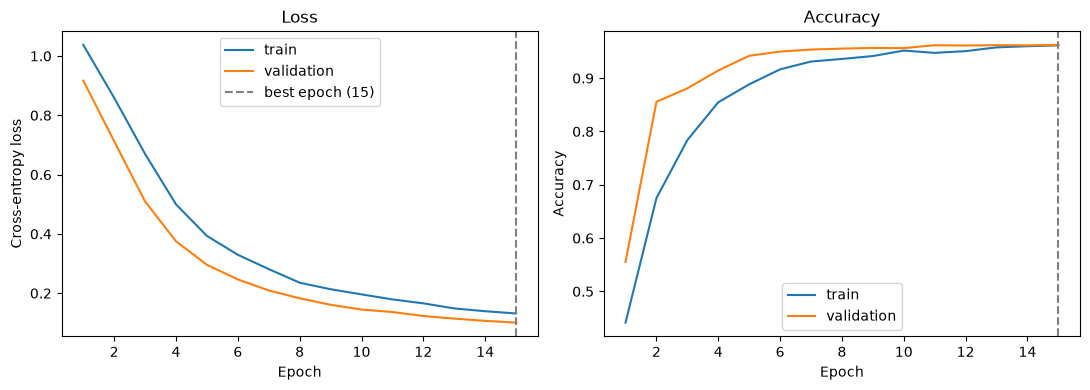

In [6]:
# ---- learning curves ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(hist) + 1)
ax[0].plot(ep, hist["loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
ax[0].axvline(best_epoch, ls="--", c="gray", label=f"best epoch ({best_epoch})")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(ep, hist["accuracy"], label="train"); ax[1].plot(ep, hist["val_accuracy"], label="validation")
ax[1].axvline(best_epoch, ls="--", c="gray")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/fig_ii3_learning_curves.png", dpi=150); plt.show()

Test accuracy: 0.9539
Macro-averaged precision 0.9595 | recall 0.9540 | F1 0.9537  (macro = unweighted mean over the 3 classes)

              precision    recall  f1-score   support

     Healthy     0.8786    1.0000    0.9354      2048
  Outer race     1.0000    1.0000    1.0000      2047
  Inner race     1.0000    0.8619    0.9258      2049

    accuracy                         0.9539      6144
   macro avg     0.9595    0.9540    0.9537      6144
weighted avg     0.9595    0.9539    0.9537      6144



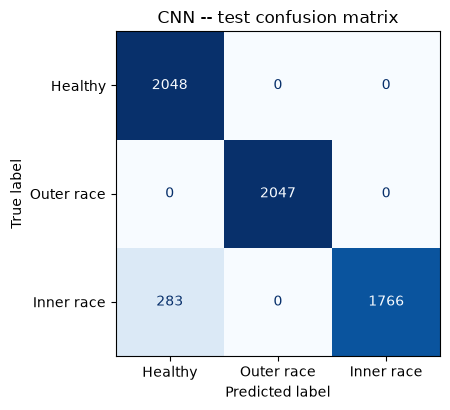

Accuracy  train 0.9657 | validation 0.9624 | test 0.9539


In [7]:
# ---- evaluation on the held-out TEST set (recordings never seen in training/validation) ----
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)

proba  = model.predict(X_test, batch_size=256, verbose=0)
y_pred = proba.argmax(axis=1)

acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
print(f"Test accuracy: {acc:.4f}")
print(f"Macro-averaged precision {p:.4f} | recall {r:.4f} | F1 {f1:.4f}  (macro = unweighted mean over the 3 classes)\n")
print(classification_report(y_test, y_pred, target_names=list(NAMES.values()), digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(cm, display_labels=list(NAMES.values())).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("CNN -- test confusion matrix"); plt.tight_layout()
plt.savefig("figures/fig_ii3_confusion_matrix.png", dpi=150); plt.show()

train_acc_final = float(model.evaluate(X_train, y_train, verbose=0)[1])
val_acc_final   = float(model.evaluate(X_val,   y_val,   verbose=0)[1])
print(f"Accuracy  train {train_acc_final:.4f} | validation {val_acc_final:.4f} | test {acc:.4f}")

### Reference: feature-based baseline on the *same* split
To judge whether the CNN is meaningfully better, an RBF-SVM on the four hand-crafted features of Part I (RMS, peak, crest factor, kurtosis) is trained on exactly the same training recordings and scored on exactly the same test segments. (Hyperparameters are the defaults; the tuned SVM from Part I Task I.4 was evaluated on a different, segment-level split, so its numbers are not directly comparable.)

In [8]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

def features(X):
    rms  = np.sqrt((X ** 2).mean(axis=1))
    peak = np.abs(X).max(axis=1)
    z    = (X - X.mean(axis=1, keepdims=True)) / X.std(axis=1, keepdims=True)
    return np.column_stack([rms, peak, peak / rms, (z ** 4).mean(axis=1)])

F_train, F_test = features(X_train_raw), features(X_test_raw)
sc = StandardScaler().fit(F_train)                                    # fitted on train only
svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(sc.transform(F_train), y_train)
svm_pred = svm.predict(sc.transform(F_test))

comparison = pd.DataFrame({
    "accuracy":  [accuracy_score(y_test, svm_pred), acc],
    "macro F1":  [f1_score(y_test, svm_pred, average="macro"), f1],
}, index=["SVM-RBF (4 features)", "1-D CNN (raw signal)"]).round(4)
print(comparison)

os.makedirs("results", exist_ok=True)
json.dump({"test_accuracy": acc, "macro_precision": p, "macro_recall": r, "macro_f1": f1,
           "svm_baseline_accuracy": float(accuracy_score(y_test, svm_pred)),
           "epochs_run": len(hist), "best_epoch": best_epoch, "n_params": int(n_params)},
          open("results/ii3_metrics.json", "w"), indent=2)

                      accuracy  macro F1
SVM-RBF (4 features)    0.9001    0.8978
1-D CNN (raw signal)    0.9539    0.9537


### Observations
- **Learning curves.** Training and validation loss both decrease steadily over all 15 epochs (validation loss 0.917 to 0.101, validation accuracy 0.555 to 0.962) and stay close together, so there is no sign of overfitting. The best epoch was epoch 15 of 15, so early stopping (patience 5) never triggered and the 15-epoch maximum ended training. The validation loss was still falling slowly, so the model is probably slightly under-trained.
- **Test performance** (6144 segments from 48 recordings never used in training or validation): accuracy 0.9539, macro precision 0.9595, macro recall 0.9540, macro F1 0.9537. Outer race: precision 1.000, recall 1.000. Healthy: precision 0.879, recall 1.000. Inner race: precision 1.000, recall 0.862.
- **Comparison with the feature baseline** on the same split: the RBF-SVM on the four Part I features reached accuracy 0.9001 and macro F1 0.8978, so the CNN is about 5.4 percentage points better in accuracy and 5.6 in macro F1. The SVM used default hyperparameters and all training segments; the CNN used one tenth of them. Each model was run once with one seed.
- **Generalisation gap.** Accuracy on the full training set is 0.9657, on validation 0.9624 and on test 0.9539, so the gap is small.

## Task II.4 -- Model Behavior (Option B: Prediction Errors)
We look at which classes, operating conditions and recordings the CNN predicts poorly, and at what the misclassified signals look like.

In [9]:
res = pd.DataFrame({"rec": rec_test, "true": y_test, "pred": y_pred, "conf": proba.max(axis=1)})
res["correct"] = res.true == res.pred
res["condition"] = res.rec.str.extract(r"(N\d+_M\d+_F\d+)")[0]      # speed_torque_force code in the file name

print("Errors:", int((~res.correct).sum()), "of", len(res), f"({(~res.correct).mean():.2%})\n")
print("Confusion counts (rows = true, columns = predicted):")
print(pd.crosstab(res.true.map(NAMES), res.pred.map(NAMES)))

print("\nAccuracy by class:");               print(res.groupby(res.true.map(NAMES)).correct.mean().round(4))
print("\nAccuracy by operating condition:"); print(res.groupby("condition").correct.mean().round(4))

pivot = res.pivot_table(index="condition", columns=res.true.map(NAMES), values="correct", aggfunc="mean")
print("\nAccuracy by condition and class:"); print(pivot.round(3))

rec_acc = res.groupby(["rec", res.true.map(NAMES)]).correct.mean().rename("accuracy").reset_index().sort_values("accuracy")
print("\nWorst 8 test recordings:"); print(rec_acc.head(8).to_string(index=False))

Errors: 283 of 6144 (4.61%)

Confusion counts (rows = true, columns = predicted):
pred        Healthy  Inner race  Outer race
true                                       
Healthy        2048           0           0
Inner race      283        1766           0
Outer race        0           0        2047

Accuracy by class:
true
Healthy       1.0000
Inner race    0.8619
Outer race    1.0000
Name: correct, dtype: float64

Accuracy by operating condition:
condition
N09_M07_F10    0.8299
N15_M01_F10    1.0000
N15_M07_F04    1.0000
N15_M07_F10    1.0000
Name: correct, dtype: float64

Accuracy by condition and class:
true         Healthy  Inner race  Outer race
condition                                   
N09_M07_F10      1.0       0.558         1.0
N15_M01_F10      1.0       1.000         1.0
N15_M07_F04      1.0       1.000         1.0
N15_M07_F10      1.0       1.000         1.0

Worst 8 test recordings:
                    rec       true  accuracy
N09_M07_F10_KI01_13.mat Inner race  0.53906

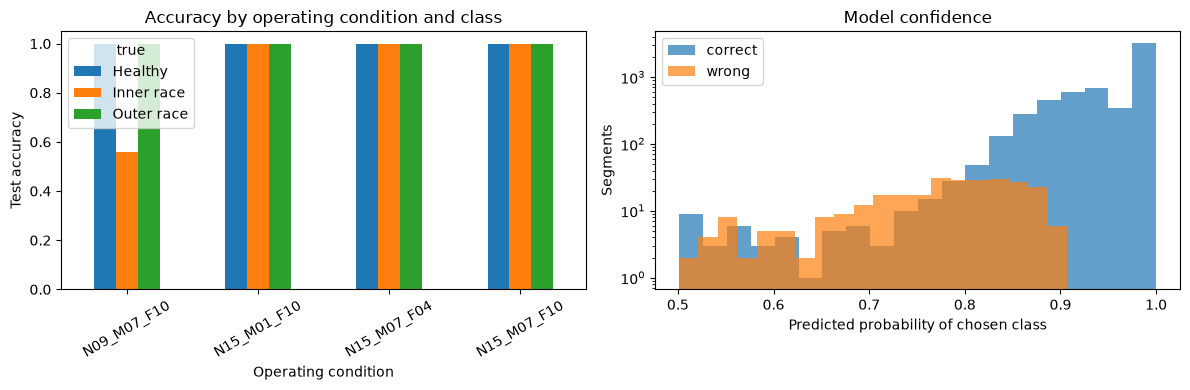

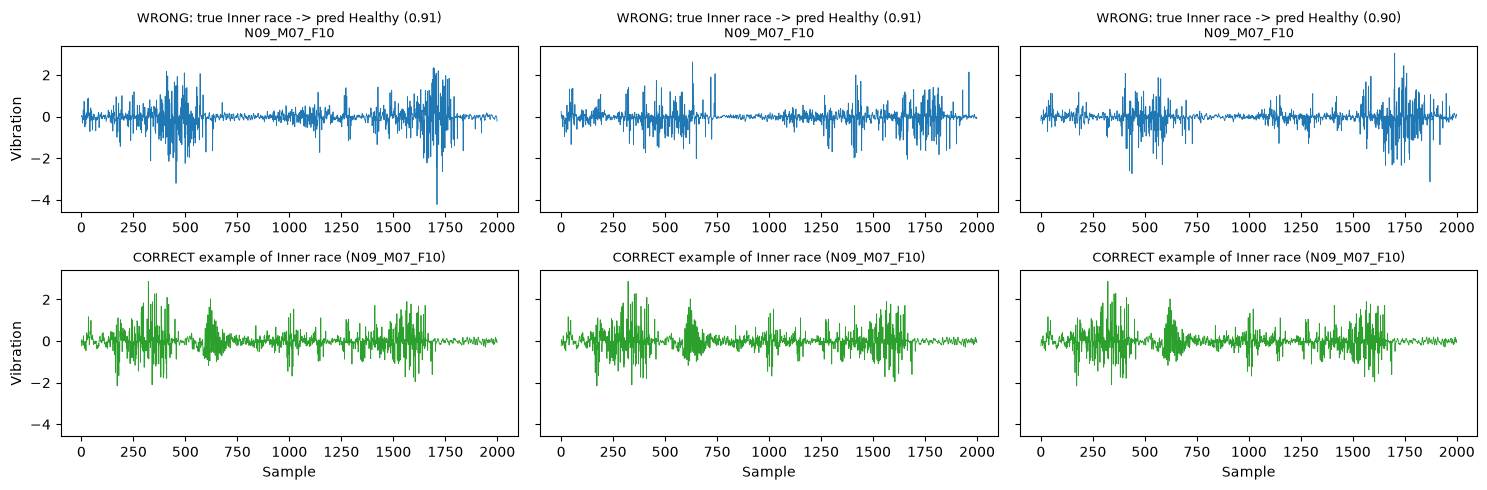

                      rms   peak  crest   kurtosis
true       status                                 
Healthy    correct  0.386  2.872  7.548  14.667000
Inner race correct  0.589  4.166  7.482  12.052000
           wrong    0.343  2.719  8.020  17.492001
Outer race correct  0.503  3.510  7.189  16.429001


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pivot.plot(kind="bar", ax=ax[0], ylim=(0, 1.05)); ax[0].set_ylabel("Test accuracy"); ax[0].set_xlabel("Operating condition")
ax[0].set_title("Accuracy by operating condition and class"); ax[0].tick_params(axis="x", rotation=30)
ax[1].hist(res.loc[res.correct, "conf"], bins=20, alpha=0.7, label="correct")
if (~res.correct).any():
    ax[1].hist(res.loc[~res.correct, "conf"], bins=20, alpha=0.7, label="wrong")
ax[1].set_xlabel("Predicted probability of chosen class"); ax[1].set_ylabel("Segments"); ax[1].set_yscale("log")
ax[1].set_title("Model confidence"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/fig_ii4_errors_by_condition.png", dpi=150); plt.show()

# ---- what do the misclassified signals look like? ----
wrong_idx = np.where(~res.correct.values)[0]
if len(wrong_idx):
    pick = wrong_idx[np.argsort(-res.conf.values[wrong_idx])][:3]          # the 3 most confident mistakes
    ok_idx = [np.where((res.true.values == res.true.values[i]) & res.correct.values)[0][0] for i in pick]
    fig, axes = plt.subplots(2, len(pick), figsize=(5 * len(pick), 5), sharey=True, squeeze=False)
    for j, (i, k) in enumerate(zip(pick, ok_idx)):
        axes[0, j].plot(X_test_raw[i], lw=0.6)
        axes[0, j].set_title(f"WRONG: true {NAMES[res.true[i]]} -> pred {NAMES[res.pred[i]]} ({res.conf[i]:.2f})\n{res.condition[i]}", fontsize=9)
        axes[1, j].plot(X_test_raw[k], lw=0.6, c="tab:green")
        axes[1, j].set_title(f"CORRECT example of {NAMES[res.true[i]]} ({res.condition[k]})", fontsize=9)
        axes[1, j].set_xlabel("Sample")
    axes[0, 0].set_ylabel("Vibration"); axes[1, 0].set_ylabel("Vibration")
    plt.tight_layout(); plt.savefig("figures/fig_ii4_misclassified_examples.png", dpi=150); plt.show()

    # signal statistics: are the mistakes statistically "unusual" for their true class?
    F = pd.DataFrame(features(X_test_raw), columns=["rms", "peak", "crest", "kurtosis"])
    F["true"] = res.true.map(NAMES).values; F["status"] = np.where(res.correct, "correct", "wrong")
    print(F.groupby(["true", "status"]).median().round(3))
else:
    print("No test errors -- see the discussion about why a perfect score needs care (single bearing per class).")

### Discussion
**Where the errors occur.** All 283 errors (4.61% of 6144 test segments) are inner-race segments predicted as healthy. Healthy and outer-race segments are classified perfectly. The errors sit in a single operating condition: N09_M07_F10 has accuracy 0.830 overall and only 0.558 for inner race, while the other three conditions are at 1.000. The five worst recordings are all KI01 (inner race) recordings at N09_M07_F10, with only 54-58% of their segments correct.

**What the misclassified signals look like.** The median RMS and peak of the wrongly classified inner-race segments (0.343 and 2.72) are close to the healthy segments (0.386 and 2.87) and much lower than the correctly classified inner-race segments (0.589 and 4.17). So the missed segments are low-amplitude and look healthy.

**Possible engineering explanations (hypotheses, not tested here).**
1. N09 is the lower rotational speed (900 rpm instead of 1500 rpm). Fault impacts are weaker and further apart at low speed, so a 2000-sample segment (about 31 ms) may contain very weak or no fault impacts.
2. Inner-race faults pass through the load zone of the bearing, so the impact strength varies and some segments look almost healthy.
3. The network may rely partly on signal amplitude, and low-amplitude segments then look healthy to it. It was also trained on only a tenth of the training segments.
4. Each class is one physical bearing, so one KI01 bearing at 900 rpm dominates the error.

**Conclusion.** The evidence shows that the errors are one-sided (inner race called healthy) and concentrated at 900 rpm. A leave-one-condition-out test, longer segments, and training on all segments would show which explanation is right.

# Individual Analysis -- Hashir Javed

## Question II.1 -- Architecture Selection

I used a 1-D CNN because every sample is a single vibration signal, 2000 numbers recorded at 64 kHz, which is about 31 ms. A damaged bearing hits its crack again and again, and in the waveform this shows up as short sharp impulses. A convolution filter looks at a small window and slides along the signal, so it can learn to detect that kind of pattern wherever it happens. In my model the first Conv1D layer has 16 filters with kernel size 32 and the second has 32 filters with kernel size 16. Max pooling shortens the signal from 2000 to 500 and then 125 steps, and global average pooling averages each of the 32 filters over the whole segment. That matters because the segments are cut at arbitrary places, so an impulse can be anywhere and the model should not care where. The whole network has only 8,851 trainable weights.

An LSTM would have to go through the 2000 time steps one after another, which is slow on a CPU, and I don't think we need its long memory since the important patterns are short. The four hand-made features from Part I (RMS, peak, crest factor, kurtosis) throw away most of the signal before the model sees it. With the raw signal the CNN can choose its own features. In my run it did better than the SVM on the four features (accuracy 0.954 against 0.900).

## Question II.2 -- Model Performance

The training and validation curves look healthy to me. Over 15 epochs the training loss went from 1.04 to 0.13 and the validation loss from 0.92 to 0.10, and the two stayed close together the whole time. Validation accuracy rose from 0.56 to 0.962, and the final accuracies were 0.966 (train), 0.962 (validation) and 0.954 (test). So I see no overfitting. The best epoch was the last one, so early stopping never triggered and the 15-epoch limit stopped training. The validation loss was still going down slowly, so the model is probably a bit under-trained. I also trained on only every 10th training segment (1,846 of 18,452) because the full run was too slow on my CPU.

The CNN did better than the baseline. An RBF-SVM on the four Part I features, with the same recording-level split and default settings, got 0.900 accuracy and 0.898 macro F1. The CNN got 0.954 accuracy and 0.954 macro F1. That is about 5.4 percentage points, and the SVM even had all the training segments.

I don't want to oversell it, though. It is one run with one seed, the SVM was not tuned (the tuned SVM from Part I used a different split, so I can't compare with it), and the test set is only 48 recordings, so a few bad recordings change the score a lot. In fact all the errors came from inner-race recordings at one operating condition (N09_M07_F10). So the CNN is better in this experiment, but I can't say by exactly how much.

## Question II.3 -- Engineering Applicability

I would recommend it for further validation, but not for real use yet. On the test recordings it got 0.954 accuracy and found every healthy and outer-race segment, but the mistakes are the worst kind. All 283 errors were inner-race faults classified as healthy, so recall for inner race is only 0.862. In a real machine that is a missed fault, which costs more than a false alarm. The errors are concentrated in one operating condition (900 rpm, N09_M07_F10), where only 56% of the inner-race segments were found, so I would not trust the model at low speed.

The most important limitation for me is the data. Each class is one physical bearing with artificially made damage, and the test set comes from the same three bearings. The network might have partly learned the identity of these bearings and not the fault type, so I can't say how it would do on a different bearing or on real wear damage. I also trained on only a tenth of the segments for 15 epochs, with one seed.

One experiment I would add is a leave-one-condition-out test: train on three operating conditions, test on the fourth, and repeat so each condition is the test condition once. I would also add other bearing codes from the same dataset so that the test bearings are never seen in training. Finally I would train on all segments with 3 seeds and use inner-race recall as the main number to compare.